In [1]:
!pip install pandas numpy matplotlib seaborn scipy scikit-learn mysql-connector-python sqlalchemy pymysql

In [2]:
import pandas as pd
from sqlalchemy import create_engine

# Настройки подключения к твоей базе MySQL
user = "root"
password = ""  # Впиши пароль, если он есть
host = "127.0.0.1"
db_name = "geo_analytics"

# Создаем подключение
engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}/{db_name}")

# Выгружаем все 5 таблиц в pandas DataFrame
print("Загрузка данных...")
df_customers = pd.read_sql("SELECT * FROM customers", engine)
df_cards = pd.read_sql("SELECT * FROM cards", engine)
df_devices = pd.read_sql("SELECT * FROM devices", engine)
df_merchants = pd.read_sql("SELECT * FROM merchants", engine)
df_transactions = pd.read_sql("SELECT * FROM transactions", engine)

print(f"Клиенты: {df_customers.shape}")
print(f"Транзакции: {df_transactions.shape}")
print("Данные успешно загружены!")

Загрузка данных...
Клиенты: (1001, 15)
Транзакции: (10001, 29)
Данные успешно загружены!


In [3]:
df_transactions.shape[0]

10001

In [4]:
import numpy as np

print("--- ДО ОЧИСТКИ ---")
print(f"Клиенты: {df_customers.shape[0]}, Транзакции: {df_transactions.shape[0]}")

# 1. Чистим битые строки (где id == название колонки)
df_customers = df_customers[df_customers['customer_id'] != 'customer_id']
df_transactions = df_transactions[df_transactions['transaction_id'] != 'transaction_id']
df_merchants = df_merchants[df_merchants['merchant_id'] != 'merchant_id']

# 2. Удаляем дубликаты
df_customers = df_customers.drop_duplicates(subset=['customer_id'])
df_transactions = df_transactions.drop_duplicates(subset=['transaction_id'])
df_merchants = df_merchants.drop_duplicates(subset=['merchant_id'])

# 3. Преобразуем дату в формат datetime
df_transactions['timestamp'] = pd.to_datetime(df_transactions['timestamp'])

# 4. Создаем колонки для месяцев и дней
df_transactions['month'] = df_transactions['timestamp'].dt.to_period('M')
df_transactions['day_of_week'] = df_transactions['timestamp'].dt.day_name()

print("\n--- ПОСЛЕ ОЧИСТКИ ---")
print(f"Клиенты: {df_customers.shape[0]}, Транзакции: {df_transactions.shape[0]}")
print(f"Мерчанты: {df_merchants.shape[0]}")

# 5. Проверяем отрицательные суммы
negative_amounts = df_transactions[df_transactions['amount'] < 0]
print(f"\nНайдено транзакций с отрицательной суммой (возвраты): {len(negative_amounts)}")

--- ДО ОЧИСТКИ ---
Клиенты: 1001, Транзакции: 10001

--- ПОСЛЕ ОЧИСТКИ ---
Клиенты: 1001, Транзакции: 10000
Мерчанты: 201

Найдено транзакций с отрицательной суммой (возвраты): 0


In [5]:
# Смотрим на последнюю строку в клиентах (или ищем ту, где customer_id не начинается на 'C')
print(df_customers.tail(1))

# Или давай жестко отфильтруем всех, чей ID начинается с 'C' (как C000001)
df_customers = df_customers[df_customers['customer_id'].astype(str).str.startswith('C')]
df_merchants = df_merchants[df_merchants['merchant_id'].astype(str).str.startswith('M')]

print("\n--- ИСПРАВЛЕННЫЕ ДАННЫЕ ---")
print(f"Клиенты: {df_customers.shape[0]}")
print(f"Мерчанты: {df_merchants.shape[0]}")

     customer_id  age  gender  country  state  city  occupation  \
1000  customer_i    0  gender  country  state  city  occupation   

      annual_income  credit_score customer_since  account_type  risk_level  \
1000              0             0     0000-00-00  account_type  risk_level   

      total_accounts  avg_monthly_balance  loan_status  
1000               0                    0  loan_status  

--- ИСПРАВЛЕННЫЕ ДАННЫЕ ---
Клиенты: 1000
Мерчанты: 200


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Настраиваем стиль графиков (чтобы выглядели профессионально)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

print("Библиотеки для графиков готовы!")

Библиотеки для графиков готовы!


In [7]:
# Объединяем таблицы (JOIN на уровне Pandas)
df_merged = df_transactions.merge(df_customers[['customer_id', 'city']], on='customer_id', how='left')
df_merged = df_merged.merge(df_merchants[['merchant_id', 'category']], on='merchant_id', how='left')

# Проверяем, что всё склеилось
print(f"Строк после объединения: {df_merged.shape[0]}")
print(df_merged[['city', 'category', 'amount']].head())

Строк после объединения: 10000
      city       category   amount
0   London         Retail  56576.8
1   Mumbai    Electronics  77231.6
2   Mumbai    Electronics  74777.6
3  Chennai     Healthcare  70054.5
4   London  Entertainment  80303.9


C:\Users\verny\AppData\Local\Temp\ipykernel_15188\1004758369.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=city_revenue, x='amount', y='city', palette='viridis')


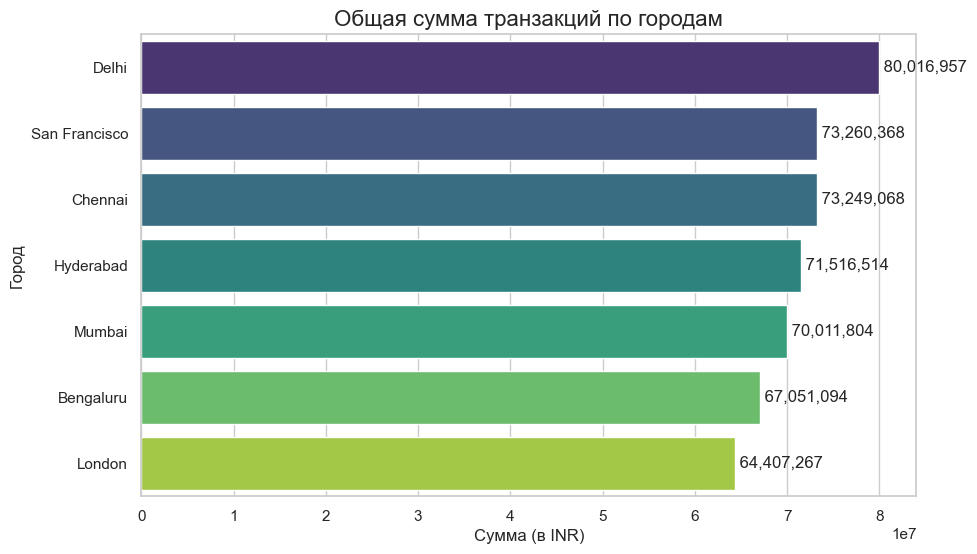

In [9]:
# Считаем общую сумму трат по городам и сортируем
city_revenue = df_merged.groupby('city')['amount'].sum().sort_values(ascending=False).reset_index()

# Строим график
plt.figure(figsize=(10, 6))
sns.barplot(data=city_revenue, x='amount', y='city', palette='viridis')
plt.title('Общая сумма транзакций по городам', fontsize=16)
plt.xlabel('Сумма (в INR)', fontsize=12)
plt.ylabel('Город', fontsize=12)

# Добавляем подписи с суммами на столбцы
for index, value in enumerate(city_revenue['amount']):
    plt.text(value, index, f' {value:,.0f}', va='center')

plt.show()

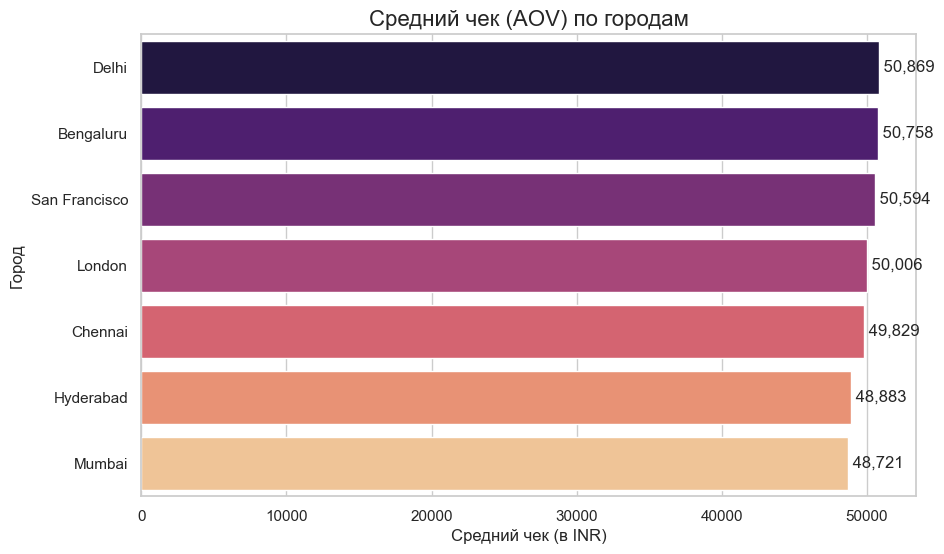

In [10]:
# Считаем средний чек (AOV) по городам
city_aov = df_merged.groupby('city')['amount'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 6))
# Используем hue=city и legend=False, чтобы убрать предупреждение
sns.barplot(data=city_aov, x='amount', y='city', hue='city', palette='magma', legend=False)

plt.title('Средний чек (AOV) по городам', fontsize=16)
plt.xlabel('Средний чек (в INR)', fontsize=12)
plt.ylabel('Город', fontsize=12)

# Добавляем подписи с суммами
for index, value in enumerate(city_aov['amount']):
    plt.text(value, index, f' {value:,.0f}', va='center')

plt.show()

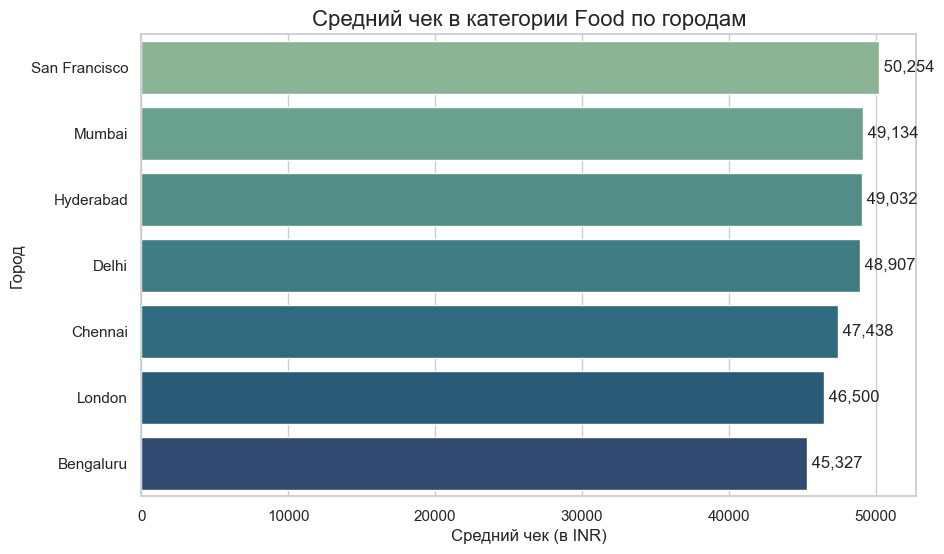

In [11]:
# Фильтруем только еду (Food)
df_food = df_merged[df_merged['category'] == 'Food']

# Считаем средний чек по городам для еды
food_aov = df_food.groupby('city')['amount'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=food_aov, x='amount', y='city', hue='city', palette='crest', legend=False)

plt.title('Средний чек в категории Food по городам', fontsize=16)
plt.xlabel('Средний чек (в INR)', fontsize=12)
plt.ylabel('Город', fontsize=12)

# Добавляем подписи с суммами
for index, value in enumerate(food_aov['amount']):
    plt.text(value, index, f' {value:,.0f}', va='center')

plt.show()

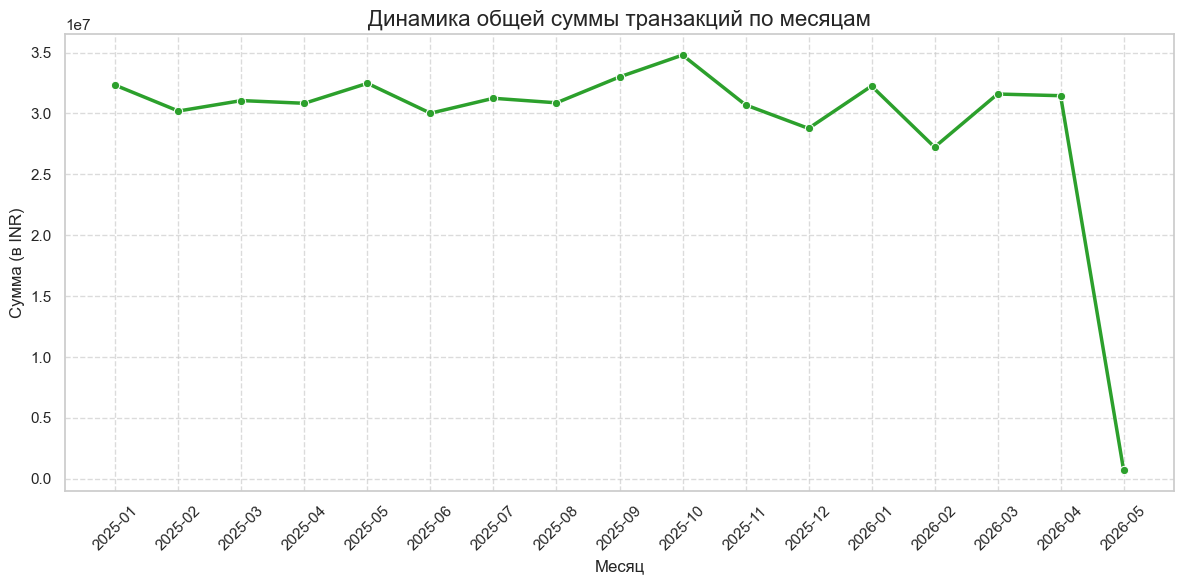

In [12]:
# Группируем по месяцам и считаем общую сумму
monthly_trend = df_transactions.groupby('month')['amount'].sum().reset_index()

# Преобразуем формат месяца для графика (чтобы было красиво)
monthly_trend['month'] = monthly_trend['month'].astype(str)

plt.figure(figsize=(12, 6))
# Строим линейный график
sns.lineplot(data=monthly_trend, x='month', y='amount', marker='o', linewidth=2.5, color='#2ca02c')

plt.title('Динамика общей суммы транзакций по месяцам', fontsize=16)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Сумма (в INR)', fontsize=12)

# Поворачиваем подписи по оси X, чтобы они не накладывались друг на друга
plt.xticks(rotation=45)

# Добавляем сетку
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

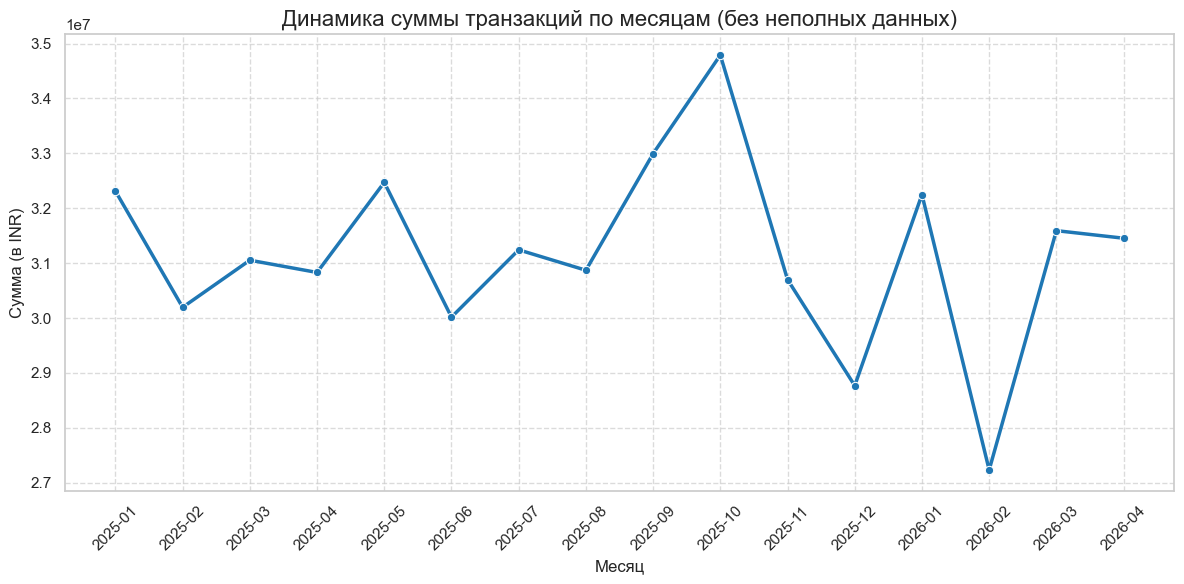

In [13]:
# Оставляем только полные месяцы (убираем май 2026 и все, что после апреля 2026)
df_filtered = df_transactions[df_transactions['month'] < '2026-05']

# Пересчитываем динамику
monthly_trend_clean = df_filtered.groupby('month')['amount'].sum().reset_index()
monthly_trend_clean['month'] = monthly_trend_clean['month'].astype(str)

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_trend_clean, x='month', y='amount', marker='o', linewidth=2.5, color='#1f77b4')

plt.title('Динамика суммы транзакций по месяцам (без неполных данных)', fontsize=16)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Сумма (в INR)', fontsize=12)

plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

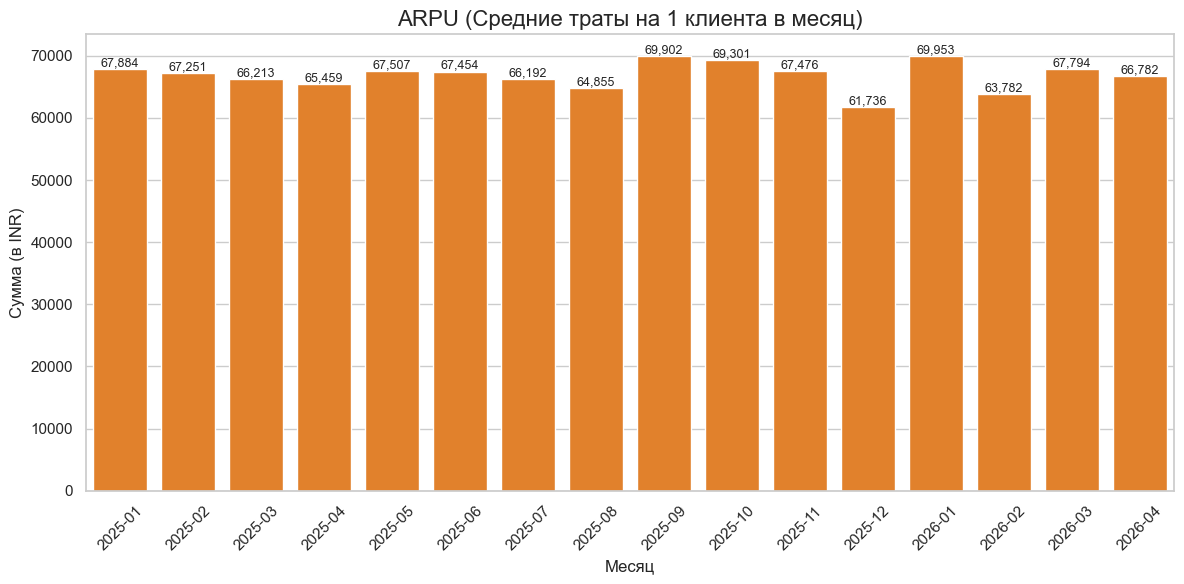

Средний ARPU за весь период: 66,846 INR в месяц


In [14]:
# 1. Считаем, сколько каждый клиент потратил в каждом месяце
user_monthly = df_filtered.groupby(['customer_id', 'month'])['amount'].sum().reset_index()

# 2. Считаем среднее значение по всем клиентам для каждого месяца (это и есть ARPU)
arpu = user_monthly.groupby('month')['amount'].mean().reset_index()
arpu['month'] = arpu['month'].astype(str)

# 3. Строим график
plt.figure(figsize=(12, 6))
sns.barplot(data=arpu, x='month', y='amount', color='#ff7f0e')

plt.title('ARPU (Средние траты на 1 клиента в месяц)', fontsize=16)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Сумма (в INR)', fontsize=12)
plt.xticks(rotation=45)

# Добавляем подписи с суммами на столбцы
for index, value in enumerate(arpu['amount']):
    plt.text(index, value, f'{value:,.0f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Выведем средний ARPU за весь период
print(f"Средний ARPU за весь период: {arpu['amount'].mean():,.0f} INR в месяц")

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("Подготовка данных для ML...")

# 1. Считаем траты каждого клиента по месяцам
user_monthly_spent = df_filtered.groupby(['customer_id', 'month'])['amount'].sum().reset_index()

# 2. Берем данные клиентов (возраст, доход, город и т.д.)
customer_features = df_customers[['customer_id', 'age', 'annual_income', 'credit_score', 'city']].copy()

# 3. Объединяем траты с профилем клиента
ml_data = user_monthly_spent.merge(customer_features, on='customer_id', how='left')

# 4. Делаем One-Hot Encoding для города (чтобы модель понимала города)
ml_data = pd.get_dummies(ml_data, columns=['city'], drop_first=True)

# 5. Определяем признаки (X) и целевую переменную (y)
# Убираем customer_id и month (они не нужны для прогноза)
X = ml_data.drop(columns=['customer_id', 'month', 'amount'])
y = ml_data['amount']

# 6. Делим на обучающую (80%) и тестовую (20%) выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Обучающая выборка: {X_train.shape[0]} строк")
print(f"Тестовая выборка: {X_test.shape[0]} строк")
print("Данные готовы к обучению!")

Подготовка данных для ML...
Обучающая выборка: 5967 строк
Тестовая выборка: 1492 строк
Данные готовы к обучению!


In [16]:
# 1. Создаем и обучаем модель
model = LinearRegression()
model.fit(X_train, y_train)

# 2. Делаем прогноз на тестовой выборке
y_pred = model.predict(X_test)

# 3. Считаем метрики качества
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== РЕЗУЛЬТАТЫ МОДЕЛИ ===")
print(f"MAE (Средняя абсолютная ошибка): {mae:,.0f} INR")
print(f"R² (Коэффициент детерминации): {r2:.4f}")

# 4. Смотрим, какие факторы влияют на траты больше всего
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', key=abs, ascending=False)

print("\n=== ВЛИЯНИЕ ФАКТОРОВ (Топ-5) ===")
print(coefficients.head(5).to_string(index=False))

=== РЕЗУЛЬТАТЫ МОДЕЛИ ===
MAE (Средняя абсолютная ошибка): 34,427 INR
R² (Коэффициент детерминации): 0.0027

=== ВЛИЯНИЕ ФАКТОРОВ (Топ-5) ===
           Feature  Coefficient
       city_Mumbai -1668.552018
    city_Hyderabad -1645.981535
      city_Chennai -1547.287780
city_San Francisco  1294.782554
       city_London  -310.034726


In [17]:
from scipy.stats import mannwhitneyu

# Берем данные по еде
df_food = df_merged[df_merged['category'] == 'Food']

# Выбираем два города для сравнения: San Francisco (лидер) и Bengaluru (аутсайдер)
sf_food = df_food[df_food['city'] == 'San Francisco']['amount']
blr_food = df_food[df_food['city'] == 'Bengaluru']['amount']

# Проводим U-тест Манна-Уитни
stat, p_value = mannwhitneyu(sf_food, blr_food, alternative='two-sided')

print("=== РЕЗУЛЬТАТЫ ПРОВЕРКИ ГИПОТЕЗЫ H1 ===")
print(f"Средний чек (San Francisco): {sf_food.mean():,.0f} INR")
print(f"Средний чек (Bengaluru): {blr_food.mean():,.0f} INR")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("\nВЫВОД: Разница СТАТИСТИЧЕСКИ ЗНАЧИМА. Средний чек в Сан-Франциско действительно выше.")
else:
    print("\nВЫВОД: Разница СЛУЧАЙНА (статистически незначима). Нельзя утверждать, что в Сан-Франциско чек выше.")

=== РЕЗУЛЬТАТЫ ПРОВЕРКИ ГИПОТЕЗЫ H1 ===
Средний чек (San Francisco): 50,254 INR
Средний чек (Bengaluru): 45,327 INR
P-value: 0.1152

ВЫВОД: Разница СЛУЧАЙНА (статистически незначима). Нельзя утверждать, что в Сан-Франциско чек выше.


In [20]:
import os

# Создаём папку на диске C (вне OneDrive)
save_dir = r"C:\geo_analytics_data"
os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(save_dir, "dashboard_data.csv")
df_merged.to_csv(save_path, index=False)

print(f"✅ Файл сохранён: {save_path}")

✅ Файл сохранён: C:\geo_analytics_data\dashboard_data.csv
